Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.5429 - loss: 1.7759 - val_accuracy: 0.7521 - val_loss: 1.3045
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7759 - loss: 1.0786 - val_accuracy: 0.8252 - val_loss: 0.8547
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8208 - loss: 0.7891 - val_accuracy: 0.8527 - val_loss: 0.6673
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8425 - loss: 0.6534 - val_accuracy: 0.8639 - val_loss: 0.5698
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8566 - loss: 0.5748 - val_accuracy: 0.8749 - val_loss: 0.5088
Learning Rate: 0.001
Test Accuracy: 87.66999840736389
Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7681 - loss: 0.9597 - val_accuracy: 0.8791 - val_loss: 0.4928
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8831 - loss: 0.4528 - val_accuracy: 0.8978 - val_loss: 0.3755
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s

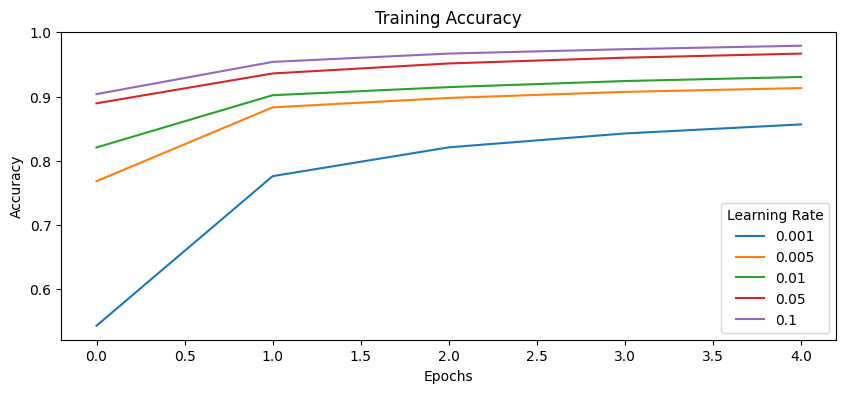

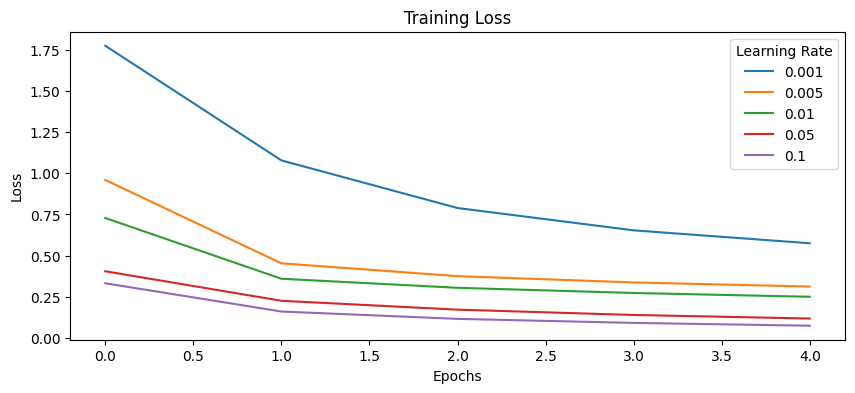

In [ ]:

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt

# 1. Load MNIST dataset
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

# 2. Normalize data
x_train = x_train / 255.0
x_test = x_test / 255.0

# 3. Learning rates
rates = [0.001, 0.005, 0.01, 0.05, 0.1]
histories = []
accuracies = []

# 4. Train models using different learning rates
for lr in rates:

    model = keras.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')
])

    model.compile(
        optimizer=keras.optimizers.SGD(learning_rate=lr),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    history = model.fit(
        x_train, y_train,
        epochs=5,
        batch_size=32,
        validation_split=0.2,
        verbose=1
    )

    loss, accuracy = model.evaluate(x_test, y_test, verbose=0)

    histories.append(history)
    accuracies.append(accuracy)

    print("Learning Rate:", lr)
    print("Test Accuracy:", accuracy * 100)


# 5. Plot accuracy and loss
plt.figure(figsize=(10, 4))

for i, h in enumerate(histories):
    plt.plot(h.history['accuracy'], label=str(rates[i]))

plt.title("Training Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend(title="Learning Rate")
plt.show()

plt.figure(figsize=(10, 4))

for i, h in enumerate(histories):
    plt.plot(h.history['loss'], label=str(rates[i]))

plt.title("Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend(title="Learning Rate")
plt.show()
